# Notebook 18 — Tổng hợp đối chứng và chi phí của nhánh A

**Câu hỏi:** Mã hóa mới tốt hơn ở đâu, so với đối chứng nào, và chi phí để tìm nghiệm là bao nhiêu?

Notebook này **không chạy lại QAOA**, không thay dữ liệu và không sửa kết quả 16–17. Nó đọc ZIP Notebook17 (chứa ZIP16), kiểm tra lại báo cáo, tính các đối chứng chính xác và đo hai triển khai cổ điển nhỏ ngay trong kernel hiện tại.

Ba khái niệm cần tách: **P_opt** = tỷ lệ lượt đo có phân công tối ưu; **thành công của một lượt chạy** = batch cuối có ít nhất một mẫu tối ưu; **thời gian** = chi phí của phần được đo. 45/45 lượt thành công không có nghĩa P_opt=100% hay thắng classical.

Chạy bằng kernel `nt409-khiem`, Restart Kernel rồi lần lượt 8 bước. Gói đã chứa đúng archive Windows bạn gửi. Không cần chạy lại Notebook13–17. Các file xuất thuộc một thư mục mới `phase4j_summary`; giữ lại đường dẫn được in ở bước1.

## Bước 1 — Xác định đầu vào và cấu hình phép đo

`SOURCE_ZIP` là kết quả Notebook17 đã chạy, không phải ZIP mã nguồn cài đặt. `TIMING_CONFIG` quy định bảy block đo, mỗi block tự chọn số lần lặp để giảm ảnh hưởng của độ phân giải đồng hồ. Random luôn thử đủ1024 phân công mỗi lần giải; exact duyệt đủ16 phân công.

Việc khởi động Python/import thư viện, audit và chuẩn bị ground truth không nằm trong thời gian giải cổ điển. Thời gian một lần giải bao gồm đọc/kiểm tra instance trong hàm, tạo RNG (random), sinh/kiểm tra ứng viên và xây dựng đầu ra. Có thêm bookkeeping rất nhỏ của bộ đo, không trừ overhead giả định.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, sys, platform
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/branch_a_summary.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.benchmark_a_campaign import load_benchmark
from src.branch_a_evidence import audit_archives
from src.branch_a_summary import (structured_reference, aggregate_rows, control_rows,
                                  measure_classical, export_summary)
SOURCE_ZIP = ROOT / 'data/benchmarks/nt409_summary_v1/notebook17_results.zip'
TIMING_CONFIG = dict(blocks=7, target_seconds=0.02, max_calls=4096, shots=1024)
CONTEXT = load_benchmark(ROOT)
FOLDER = ROOT / 'data/reference_results/phase4j_summary' / ('summary_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
FOLDER.mkdir(parents=True, exist_ok=False)
pd.set_option('display.max_columns', 20)
print('Đầu vào:', SOURCE_ZIP)
print('Kết quả mới:', FOLDER)
print('Môi trường đo cổ điển:', platform.platform(), platform.python_version())

Đầu vào: c:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\benchmarks\nt409_summary_v1\notebook17_results.zip
Kết quả mới: c:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase4j_summary\summary_20261011T093559932161Z
Môi trường đo cổ điển: Windows-11-10.0.26200-SP0 3.12.14


## Bước 2 — Audit archive16 và17, không chạy lại thuật toán

Kiểm tra hash/đủ tệp, thiết kế, seed, mã nguồn (chấp nhận LF/CRLF), ledger, nghiệm giải mã, năng lượng và metric. Sau đó tính lại các hàng CSV từ report rồi đối chiếu CSV đã xuất. Các mạch QAOA không được thực thi.

**Bước này có thể mất vài phút** vì kiểm tra nhiều mẫu thô; tiến độ xuất sau mỗi5 report. Nếu thiếu lượt, dữ liệu hoặc mã nguồn khác thì dừng để xử lý, không bỏ audit hoặc tự điền0. Runtime Windows của dữ liệu cũ có thể khác runtime hiện tại; khác biệt này được ghi lại, không tự sửa metadata.

In [2]:
EVIDENCE = audit_archives(SOURCE_ZIP, CONTEXT, progress=True)
assert len(EVIDENCE['rows']) == 92
for name, details in EVIDENCE['sources'].items():
    print(name, details['campaign_id'], details['statuses'])
    print('Runtime ghi nhận:', details['environment']['core']['runtime'])
print('AUDIT PASS. Thời gian audit (không phải thời gian giải):', round(EVIDENCE['audit_seconds'], 2), 'giây')

Audit Notebook 16: 1/55
Audit Notebook 16: 5/55
Audit Notebook 16: 10/55
Audit Notebook 16: 15/55
Audit Notebook 16: 20/55
Audit Notebook 16: 25/55
Audit Notebook 16: 30/55
Audit Notebook 16: 35/55
Audit Notebook 16: 40/55
Audit Notebook 16: 45/55
Audit Notebook 16: 50/55
Audit Notebook 16: 55/55
Audit Notebook 17: 1/55
Audit Notebook 17: 5/55
Audit Notebook 17: 10/55
Audit Notebook 17: 15/55
Audit Notebook 17: 20/55
Audit Notebook 17: 25/55
Audit Notebook 17: 30/55
Audit Notebook 17: 35/55
Audit Notebook 17: 40/55
Audit Notebook 17: 45/55
Audit Notebook 17: 50/55
Audit Notebook 17: 55/55
notebook16 20261010T081035000606Z {'probe:passed': 9, 'trial:completed': 46}
Runtime ghi nhận: {'python_version': '3.12.14', 'platform': 'Windows-11-10.0.26200-SP0', 'numpy_version': '2.5.3', 'scipy_version': '1.18.1', 'qiskit_version': '2.5.2', 'qiskit_optimization_version': '0.7.0', 'qiskit_aer_version': '0.17.2'}
notebook17 20261011T034920393465Z {'probe:passed': 9, 'trial:completed': 46}
Runtime g

## Bước 3 — Tính đối chứng chính xác

1. **Uniform encoding:** lấy đều các bit của mã hóa tương ứng, kể cả y và slack; xác suất được tính bằng tham chiếu đã audit.
2. **Random assignment:** mỗi task chọn host0/1 đều nhau, suy ra host bật từ các task. Phân công quá tải là thất bại; không sửa nghiệm. Duyệt16 phân công cho xác suất chính xác, không cần ước lượng bằng một đợt random.
3. **Exact enumeration:** duyệt toàn bộ phân công, chọn nghiệm tốt nhất. Đây là solver cổ điển sẽ được đo ở bước5.

Với đối chứng lấy mẫu độc lập có xác suất tối ưu q, xác suất tìm thấy ít nhất một nghiệm trong S mẫu là `1-(1-q)^S`. **Không áp công thức này cho P_opt gộp nhiều mạch QAOA khác nhau.** Trên input vô nghiệm, P_opt để trống/null vì không tồn tại nghiệm tối ưu khả thi; P_feasible=0.

In [3]:
REFERENCES = {name: structured_reference(instance) for name, instance in CONTEXT['instances'].items()}
CONTROLS = control_rows(EVIDENCE, REFERENCES)
display(pd.DataFrame(REFERENCES.values())[['instance_id','assignments','feasible_count','optimal_count','optimum']])
control_table = pd.DataFrame(CONTROLS)
control_table['P_feasible_%'] = 100 * control_table['feasible_probability']
control_table['P_opt_%'] = 100 * control_table['optimal_probability']
display(control_table[['instance_id','method','P_feasible_%','P_opt_%','optimal_batch_1024_probability']])
print('Kiểm tra: random P_opt choice=6.25%, tight=25%, reference=6.25%.')
print('Xác suất batch gần1 có thể hiển thị thành1 do làm tròn; không phải bảo đảm tuyệt đối của random.')

,instance_id,assignments,feasible_count,optimal_count,optimum
0,p1_choice,16,11,1,1.0
1,p1_tight,16,4,4,2.0
2,p0_reference,16,1,1,2.0
3,p1_infeasible,16,0,0,NaN


,instance_id,method,P_feasible_%,P_opt_%,optimal_batch_1024_probability
0,p1_choice,uniform_one_hot_slack_v1_1,1.171875,0.097656,0.632300
1,p1_tight,uniform_one_hot_slack_v1_1,0.390625,0.390625,0.981827
2,p0_reference,uniform_one_hot_slack_v1_1,0.097656,0.097656,0.632300
3,p1_infeasible,uniform_one_hot_slack_v1_1,0.000000,NaN,NaN
4,p1_choice,uniform_two_host_binary_v1,18.750000,1.562500,1.000000
5,p1_tight,uniform_two_host_binary_v1,6.250000,6.250000,1.000000
6,p0_reference,uniform_two_host_binary_v1,1.562500,1.562500,1.000000
7,p1_infeasible,uniform_two_host_binary_v1,0.000000,NaN,NaN
8,p1_choice,random_assignment_y_inferred,68.750000,6.250000,1.000000
9,p1_tight,random_assignment_y_inferred,25.000000,25.000000,1.000000


Kiểm tra: random P_opt choice=6.25%, tight=25%, reference=6.25%.
Xác suất batch gần1 có thể hiển thị thành1 do làm tròn; không phải bảo đảm tuyệt đối của random.


## Bước 4 — Đọc chất lượng QAOA theo instance và độ sâu

Chỉ tổng hợp45 lượt chính của mỗi encoding; negative-control tách riêng. `optimal_count/final_shots` là P_opt. `found_optimal_runs/runs` là tỷ lệ lượt có ít nhất một mẫu tối ưu. `optimal_probability_sd` là độ lệch chuẩn giữa5 seed, **không phải khoảng tin cậy**.

`lift_own_uniform` so với uniform cùng encoding. `lift_structured_random` so với random chọn host rồi suy ra y. Lift>1 chỉ nghĩa là tỷ lệ mẫu tối ưu cao hơn đối chứng tương ứng, chưa tính chi phí đào tạo QAOA.

Ở choice, hãy xem đồng thời P_feasible và P_opt: nhiều nghiệm khả thi hơn có thể vẫn ít nghiệm một host hơn. Ở tight/reference, các phân công khả thi đều tối ưu theo số host bật.

In [4]:
GROUPS = aggregate_rows(EVIDENCE['rows'], REFERENCES)
quality = pd.DataFrame(GROUPS)
quality['P_opt_%'] = 100 * quality['optimal_probability']
quality['P_feasible_%'] = 100 * quality['feasible_probability']
display(quality[['encoding','instance_id','p','runs','optimal_count','final_shots','P_opt_%',
                 'P_feasible_%','found_optimal_runs','lift_own_uniform','lift_structured_random']])
negative = pd.DataFrame([r for r in EVIDENCE['rows'] if r['role']=='negative_control'])
display(negative[['encoding','instance_id','status','found_valid','optimal_probability']])

,encoding,instance_id,p,runs,optimal_count,final_shots,P_opt_%,P_feasible_%,found_optimal_runs,lift_own_uniform,lift_structured_random
0,one_hot_slack_v1_1,p1_choice,1,5,13,5120,0.253906,2.207031,3,2.600000,0.040625
1,one_hot_slack_v1_1,p1_choice,2,5,5,5120,0.097656,2.031250,4,1.000000,0.015625
2,one_hot_slack_v1_1,p1_choice,3,5,5,5120,0.097656,2.382812,3,1.000000,0.015625
3,one_hot_slack_v1_1,p1_tight,1,5,14,5120,0.273438,0.273438,4,0.700000,0.010937
4,one_hot_slack_v1_1,p1_tight,2,5,21,5120,0.410156,0.410156,5,1.050000,0.016406
5,one_hot_slack_v1_1,p1_tight,3,5,0,5120,0.000000,0.000000,0,0.000000,0.000000
6,one_hot_slack_v1_1,p0_reference,1,5,3,5120,0.058594,0.058594,2,0.600000,0.009375
7,one_hot_slack_v1_1,p0_reference,2,5,4,5120,0.078125,0.078125,3,0.800000,0.012500
8,one_hot_slack_v1_1,p0_reference,3,5,0,5120,0.000000,0.000000,0,0.000000,0.000000
9,two_host_binary_v1,p1_choice,1,5,162,5120,3.164062,21.464844,5,2.025000,0.506250


,encoding,instance_id,status,found_valid,optimal_probability
0,one_hot_slack_v1_1,p1_infeasible,completed,False,None
1,two_host_binary_v1,p1_infeasible,completed,False,None


## Bước 5 — Đo đối chứng cổ điển trên máy hiện tại

Hai solver cùng dùng dữ liệu gốc và suy ra y từ host được sử dụng. Exact kiểm tra hết16 phân công; random thử đủ1024 phân công, không dừng khi đã gặp optimum và không được truyền trước nghiệm tối ưu vào solver. Ground truth chỉ dùng để đánh giá đầu ra sau giải.

Mỗi phương pháp được đo nhiều block sau calibration. Bảng báo median/min/max **thời gian trung bình mỗi lần giải trong block**, không phải thời gian của từng ứng viên. Các lần lặp là phép đo thời gian, không phải thêm seed huấn luyện QAOA. Đóng ứng dụng nặng để giảm nhiễu. Không cần thay cấu hình rồi đo lại đến khi có số đẹp.

In [5]:
TIMINGS = []
for item in CONTEXT['manifest']['instances']:
    if item['role'] != 'benchmark': continue
    name = item['instance_id']
    print('Đo classical:', name, flush=True)
    TIMINGS.extend(measure_classical(CONTEXT['instances'][name], **TIMING_CONFIG))
timing_table = pd.DataFrame(TIMINGS)
timing_table['median_ms'] = 1000 * timing_table['seconds_median']
timing_table['min_ms'] = 1000 * timing_table['seconds_min']
timing_table['max_ms'] = 1000 * timing_table['seconds_max']
display(timing_table[['instance_id','method','median_ms','min_ms','max_ms','calls_per_block',
                      'successful_calls','total_calls']])

Đo classical: p1_choice
Đo classical: p1_tight
Đo classical: p0_reference


,instance_id,method,median_ms,min_ms,max_ms,calls_per_block,successful_calls,total_calls
0,p1_choice,exact_enumeration,0.033974,0.032572,0.035362,1024,7168,7168
1,p1_choice,random_assignment,3.577425,3.483037,3.617463,8,56,56
2,p1_tight,exact_enumeration,0.032740,0.032198,0.033588,1024,7168,7168
3,p1_tight,random_assignment,3.587188,3.462200,3.697400,8,56,56
4,p0_reference,exact_enumeration,0.032610,0.031943,0.033481,1024,7168,7168
5,p0_reference,random_assignment,3.503987,3.462712,3.572363,8,56,56


## Bước 6 — So sánh chất lượng và thời gian với đúng phạm vi

QAOA: median của5 trường `total_seconds` lịch sử, gồm phần thực thi mỗi trial; preprocessing/model reference được ghi riêng và không phân bổ giả định cho từng trial. Classical: median block của bước5, gồm input validation trong solver, RNG, kiểm tra ứng viên và đầu ra; không gồm import, calibration và chuẩn bị ground truth.

Đây là **so sánh mô tả chi phí solver đã ghi nhận**, không phải thí nghiệm đồng thời dưới cùng tải máy hay tổng thời gian end-to-end. Nếu Python/OS khác, ghi rõ đó là kiểm thử chéo môi trường. Không quy đổi thời gian simulator thành thời gian máy quantum. Audit đọc kết quả cũ không phải thời gian giải lại QAOA.

Chưa có FF/BFD/MILP, do đó không kết luận so với mọi thuật toán cổ điển. Không tính TTS99 từ P_opt gộp; tỷ lệ thành công QAOA quan sát từ5 seed cũng chưa xác nhận độ tin cậy99%.

In [6]:
cost_rows = []
for g in GROUPS:
    cost_rows.append(dict(instance_id=g['instance_id'],method=g['encoding'],p=g['p'],
        median_solver_seconds=g['seconds_median'],batch_success=g['observed_run_success'],
        success_kind='observed across 5 training seeds',timing_kind='historical QAOA trial'))
for t in TIMINGS:
    ref = REFERENCES[t['instance_id']]
    success = (1.0 if ref['optimum'] is not None else None) if t['method']=='exact_enumeration' else next(
        c['optimal_batch_1024_probability'] for c in CONTROLS
        if c['instance_id']==t['instance_id'] and c['method']=='random_assignment_y_inferred')
    cost_rows.append(dict(instance_id=t['instance_id'],method=t['method'],p=None,
        median_solver_seconds=t['seconds_median'],batch_success=success,
        success_kind='deterministic exact' if t['method']=='exact_enumeration' else 'analytic IID 1024 draws',
        timing_kind='current-session classical blocks'))
cost_table = pd.DataFrame(cost_rows)
display(cost_table)
for name, details in EVIDENCE['sources'].items():
    print(name, 'preprocessing ghi nhận riêng:', details['preprocessing_seconds'], 'giây')
print('Tổng giây trial QAOA theo encoding:')
display(quality.groupby('encoding')[['total_seconds','total_nfev','total_algorithm_shots']].sum())

,instance_id,method,p,median_solver_seconds,batch_success,success_kind,timing_kind
0,p1_choice,one_hot_slack_v1_1,1.0,4.468238,0.6,observed across 5 training seeds,historical QAOA trial
1,p1_choice,one_hot_slack_v1_1,2.0,10.238855,0.8,observed across 5 training seeds,historical QAOA trial
2,p1_choice,one_hot_slack_v1_1,3.0,17.084654,0.6,observed across 5 training seeds,historical QAOA trial
3,p1_tight,one_hot_slack_v1_1,1.0,4.670508,0.8,observed across 5 training seeds,historical QAOA trial
4,p1_tight,one_hot_slack_v1_1,2.0,5.072076,1.0,observed across 5 training seeds,historical QAOA trial
5,p1_tight,one_hot_slack_v1_1,3.0,6.170871,0.0,observed across 5 training seeds,historical QAOA trial
6,p0_reference,one_hot_slack_v1_1,1.0,20.680834,0.4,observed across 5 training seeds,historical QAOA trial
7,p0_reference,one_hot_slack_v1_1,2.0,58.138859,0.6,observed across 5 training seeds,historical QAOA trial
8,p0_reference,one_hot_slack_v1_1,3.0,89.666400,0.0,observed across 5 training seeds,historical QAOA trial
9,p1_choice,two_host_binary_v1,1.0,2.614807,1.0,observed across 5 training seeds,historical QAOA trial


notebook16 preprocessing ghi nhận riêng: 2.7189287999972294 giây
notebook17 preprocessing ghi nhận riêng: 0.8147508999998081 giây
Tổng giây trial QAOA theo encoding:


,total_seconds,total_nfev,total_algorithm_shots
encoding,,,
one_hot_slack_v1_1,1108.533832,1976,2115584
two_host_binary_v1,199.456259,2002,2142208


## Bước 7 — Đọc biểu đồ chất lượng

Đường màu biểu diễn P_opt ở p1/2/3; thanh sai số là SD giữa5 seed. Đường random có cấu trúc là đối chứng mạnh hơn uniform bit; đường uniform compact cho biết lợi ích vượt lên trên việc chỉ thu hẹp không gian biểu diễn.

Nếu compact tốt hơn one-hot nhưng vẫn thấp hơn random có cấu trúc, chỉ kết luận mã hóa cải thiện QAOA cũ. Nếu cao hơn random, vẫn cần xem chi phí ở bước6. Không chọn riêng instance tốt để kết luận cho toàn bộ dữ liệu.

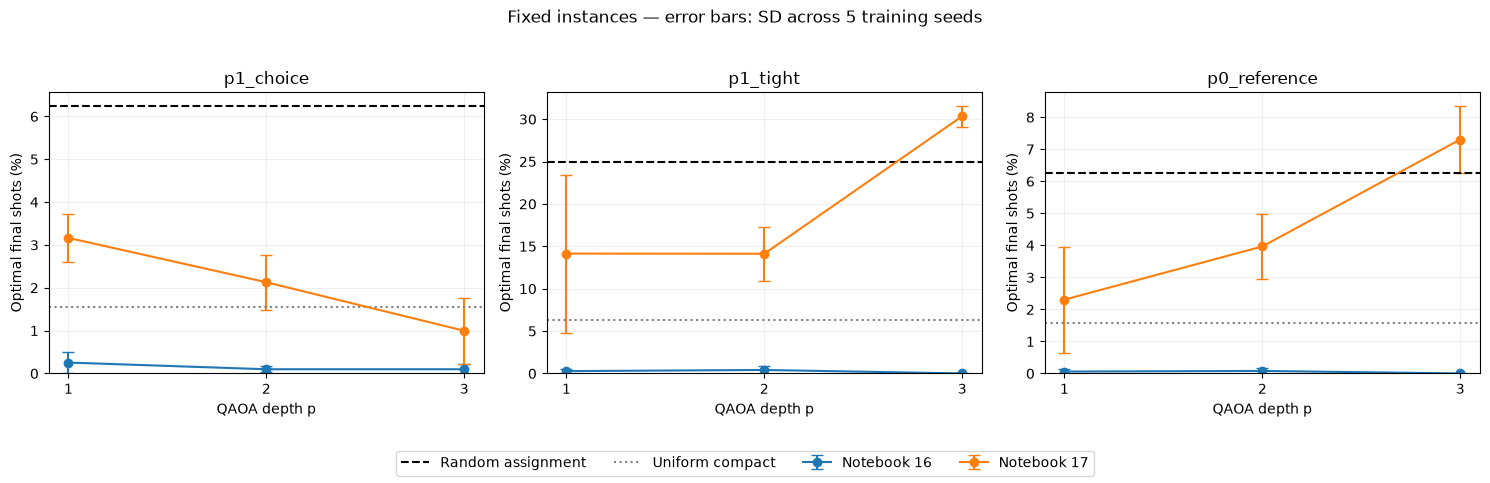

In [7]:
names = ['p1_choice','p1_tight','p0_reference']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, name in zip(axes, names):
    for encoding, label in [('one_hot_slack_v1_1','Notebook 16'),('two_host_binary_v1','Notebook 17')]:
        part = quality[(quality['instance_id']==name) & (quality['encoding']==encoding)].sort_values('p')
        ax.errorbar(part['p'],part['P_opt_%'],yerr=100*part['optimal_probability_sd'],marker='o',capsize=4,label=label)
    ax.axhline(100*REFERENCES[name]['optimal_probability'],color='black',linestyle='--',label='Random assignment')
    uniform = quality[(quality['instance_id']==name)&(quality['encoding']=='two_host_binary_v1')]['uniform_optimal_probability'].iloc[0]
    ax.axhline(100*uniform,color='gray',linestyle=':',label='Uniform compact')
    ax.set(title=name,xlabel='QAOA depth p',ylabel='Optimal final shots (%)',xticks=[1,2,3])
    ax.set_ylim(bottom=0);ax.grid(alpha=.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',ncol=4)
fig.suptitle('Fixed instances — error bars: SD across 5 training seeds')
fig.tight_layout(rect=[0,.10,1,.95])
fig.savefig(FOLDER/'summary_quality.png',dpi=150)
plt.show()

## Bước 8 — Xuất bằng chứng và kết luận

ZIP mới chứa bảng per-run/per-group, các đối chứng, timing block thô, môi trường, báo cáo audit, biểu đồ và nguyên ZIP Notebook17 (bên trong có baseline16). Input được kiểm tra lại SHA trước khi xuất; không sửa file gốc.

Kết luận cần trả lời: (1) mã hóa có cải thiện không; (2) có vượt uniform và random có cấu trúc không; (3) thời gian solver đã đo như thế nào; (4) còn giới hạn gì. Không coi FAIL/zero là dữ liệu cần xóa. Campaign không đầy đủ sẽ bị chặn ở bước2.

**Sau khi chạy:** Save notebook, gửi ZIP in bên dưới và file notebook đã Save. Bạn không cần gửi riêng từng CSV/PNG nếu đã gửi ZIP. Số đo Linux kiểm thử đi kèm gói cài đặt không được trộn với timing Windows của bạn.

In [8]:
cost_table.to_csv(FOLDER/'cost_comparison.csv',index=False,encoding='utf-8-sig')
ARCHIVE = export_summary(FOLDER, SOURCE_ZIP, EVIDENCE, REFERENCES, CONTROLS, GROUPS, TIMINGS, TIMING_CONFIG)
print('HOÀN TẤT tổng hợp và đo classical; không chạy thêm QAOA.')
print('Gửi ZIP:', ARCHIVE)
print('Kèm file 18_branch_a_controlled_summary.ipynb sau khi Save.')

HOÀN TẤT tổng hợp và đo classical; không chạy thêm QAOA.
Gửi ZIP: c:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase4j_summary\summary_20261011T093559932161Z\summary_20261011T093559932161Z.zip
Kèm file 18_branch_a_controlled_summary.ipynb sau khi Save.
